# 25 · Contours, Hierarchy and Centroids

LRT4012 Robot Vision · Fall 2026


## Boundaries, regions and shape measurements

Contours are ordered boundary point sequences. `RETR_EXTERNAL` returns outer boundaries; `RETR_TREE` also reports nested contours. `CHAIN_APPROX_SIMPLE` compresses straight boundary runs. Binary-mask quality determines the measured shape.

$$m_{pq}=\sum_{x,y}x^p y^q B(x,y),\qquad c_x=m_{10}/m_{00},\quad c_y=m_{01}/m_{00}.$$

$B$ is a binary region, $(x,y)$ are pixel coordinates, $p,q$ are nonnegative integer orders, $m_{pq}$ is a spatial moment, and $(c_x,c_y)$ is the centroid. The formula describes raster moments; `cv2.moments(contour)` uses polygon moments, so area may differ from the count of foreground pixels. A zero $m_{00}$ has no defined centroid.


In [1]:
from pathlib import Path
import os, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repository():
    candidates = []
    if os.environ.get('VISION_ROBOTICA_REPO'):
        candidates.append(Path(os.environ['VISION_ROBOTICA_REPO']).expanduser())
    candidates += [Path.cwd(), *Path.cwd().parents]
    for root in candidates:
        if (root / 'requirements.txt').is_file() and (root / 'imagenes').is_dir():
            return root.resolve()
    raise FileNotFoundError('Open Jupyter inside the course repository, or set VISION_ROBOTICA_REPO to its root.')

REPO = find_repository()
IMAGE_DIR = REPO / 'imagenes'  # Read-only official resources.
# Save your own notebook and generated images in student_work/ and student_work/imagenes/.
cv2.setRNGSeed(4012)
cv2.setNumThreads(1)
rng = np.random.default_rng(4012)
plt.rcParams.update({'figure.dpi':100, 'font.size':10})

def load_image(name, max_side=640):
    image = cv2.imread(str(IMAGE_DIR / name), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f'Official resource could not be read: {name}')
    h, w = image.shape[:2]
    if max(h, w) > max_side:
        scale = max_side / max(h, w)
        image = cv2.resize(image, (round(w*scale), round(h*scale)), interpolation=cv2.INTER_AREA)
    return image

def gray(image): return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

def panels(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4*len(images), 3.5), squeeze=False)
    for ax, im, title in zip(axes[0], images, titles):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    plt.show()

def timed_ms(fn, repetitions=30):
    fn()  # Warm-up.
    times = []
    for _ in range(repetitions):
        start = time.perf_counter()
        fn()
        times.append((time.perf_counter()-start)*1000)
    return float(np.median(times))

def mask_metrics(prediction, reference):
    a, b = prediction.astype(bool), reference.astype(bool)
    tp = int(np.count_nonzero(a & b))
    fp = int(np.count_nonzero(a & ~b))
    fn = int(np.count_nonzero(~a & b))
    return {'IoU': tp/(tp+fp+fn) if tp+fp+fn else 1.0,
            'precision': tp/(tp+fp) if tp+fp else np.nan,
            'recall': tp/(tp+fn) if tp+fn else np.nan,
            'F1': 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 1.0}


In [2]:
def object_scene(touching=False):
    image=np.full((240,360,3),220,np.uint8)
    labels=np.zeros((240,360),np.int32)
    centers=[(85,110),(137 if touching else 180,110),(275,140)]
    colors=[(40,40,190),(40,40,190),(40,155,40)]
    for i,(center,color) in enumerate(zip(centers,colors),start=1):
        mask=np.zeros(labels.shape,np.uint8)
        cv2.circle(mask,center,32,255,-1)
        labels[mask>0]=i; image[mask>0]=color
    return image,labels


def describe_contours(mask):
    contours,hierarchy=cv2.findContours(mask,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    rows=[]; valid=[]
    for contour in contours:
        area=cv2.contourArea(contour); perimeter=cv2.arcLength(contour,True)
        moment=cv2.moments(contour)
        if area<20 or perimeter<=0 or moment['m00']==0:continue
        x,y,w,h=cv2.boundingRect(contour)
        hull_area=cv2.contourArea(cv2.convexHull(contour))
        hu=cv2.HuMoments(moment).ravel()
        row={'id':len(valid)+1,'area_px2':area,'perimeter_px':perimeter,
             'cx_px':moment['m10']/moment['m00'],'cy_px':moment['m01']/moment['m00'],
             'circularity':4*np.pi*area/perimeter**2,'solidity':area/hull_area if hull_area>0 else np.nan,
             'aspect_ratio':w/h,'extent':area/(w*h)}
        row.update({f'Hu{i+1}_signed_log':float(-np.sign(v)*np.log10(abs(v)+1e-30)) for i,v in enumerate(hu)})
        rows.append(row);valid.append(contour)
    columns=['id','area_px2','perimeter_px','cx_px','cy_px','circularity','solidity','aspect_ratio','extent']+[f'Hu{i}_signed_log' for i in range(1,8)]
    return valid,pd.DataFrame(rows,columns=columns)

def draw_contours(image,contours,table):
    result=image.copy()
    cv2.drawContours(result,contours,-1,(0,180,255),2)
    for row in table.to_dict('records'):
        center=(round(row['cx_px']),round(row['cy_px']))
        cv2.circle(result,center,3,(255,0,0),-1)
        cv2.putText(result,str(row['id']),center,cv2.FONT_HERSHEY_SIMPLEX,0.5,(0,0,0),1)
    return result


,id,area_px2,perimeter_px,cx_px,cy_px
0,1,3118.0,211.48,275.0,140.0
1,2,3118.0,211.48,180.0,110.0
2,3,3118.0,211.48,85.0,110.0


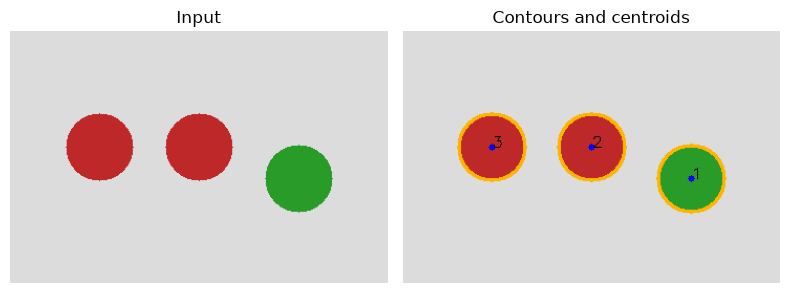

,next,previous,first_child,parent
0,1,-1,-1,-1
1,2,0,-1,-1
2,-1,1,3,-1
3,-1,-1,-1,2


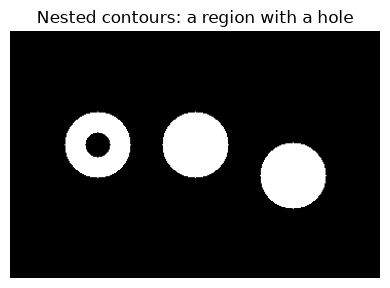

In [3]:
image,labels=object_scene(); mask=np.uint8(labels>0)*255
contours,table=describe_contours(mask)
display(table[['id','area_px2','perimeter_px','cx_px','cy_px']].round(2))
panels([image,draw_contours(image,contours,table)],['Input','Contours and centroids'])
# A hole produces a parent-child relation.
ring=mask.copy(); cv2.circle(ring,(85,110),12,0,-1)
all_contours,hierarchy=cv2.findContours(ring,cv2.RETR_TREE,cv2.CHAIN_APPROX_SIMPLE)
display(pd.DataFrame(hierarchy[0] if hierarchy is not None else [],columns=['next','previous','first_child','parent']))
panels([ring],['Nested contours: a region with a hole'])


## Robotic interpretation

Explain why hole boundaries must not be counted as separate parts. Identify how a centroid in pixels differs from a robot grasp position in meters. State what calibration and depth information are missing.


## References

- [OpenCV: thresholding](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html)
- [OpenCV: watershed](https://docs.opencv.org/4.13.0/d3/db4/tutorial_py_watershed.html)
- [OpenCV: contours](https://docs.opencv.org/4.x/d3/d05/tutorial_py_table_of_contents_contours.html)
